In [1]:
import anomaly_detection as ad
import pandas as pd
import os
import sys
import matplotlib.pyplot as plt

from analysis import *

In [2]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

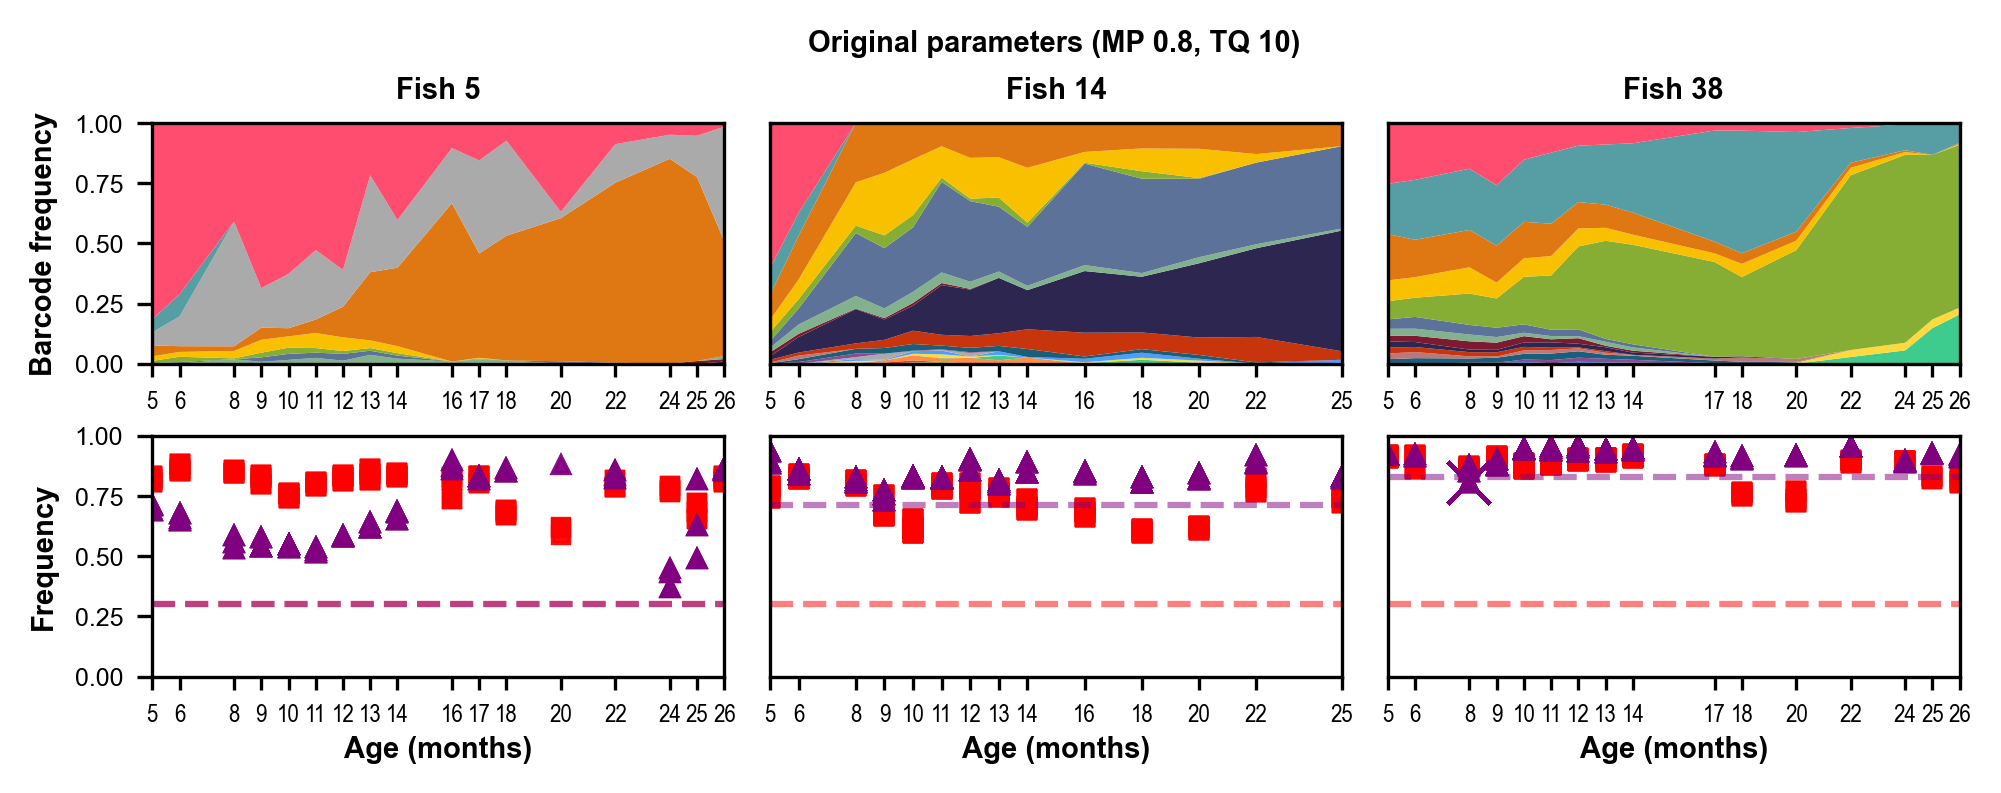

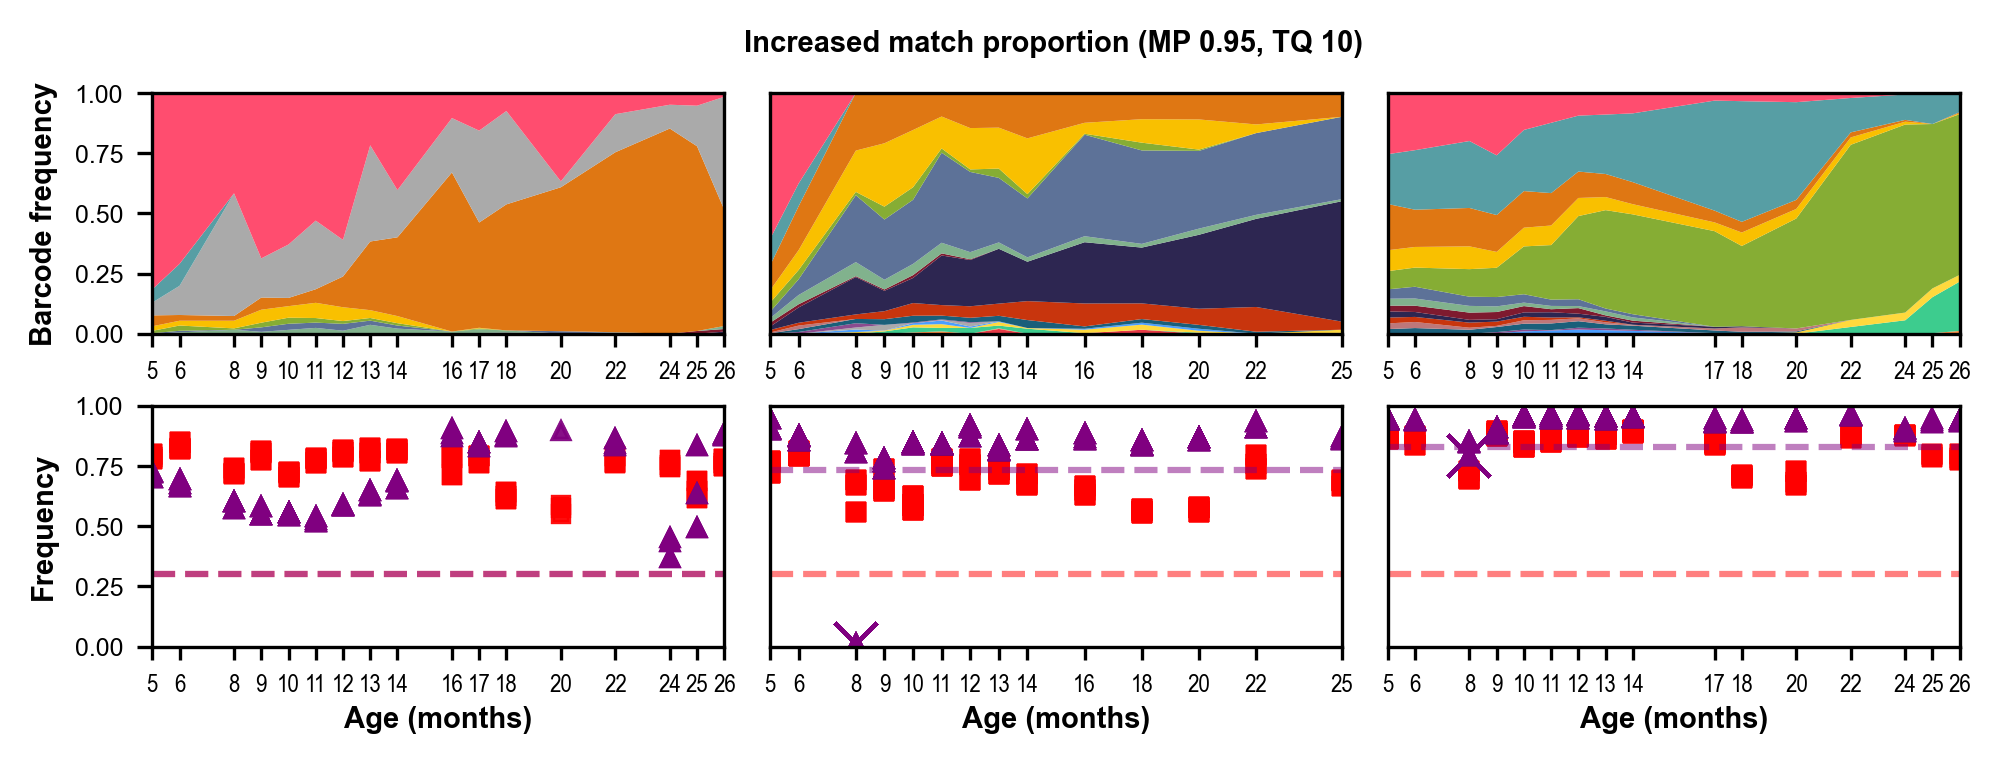

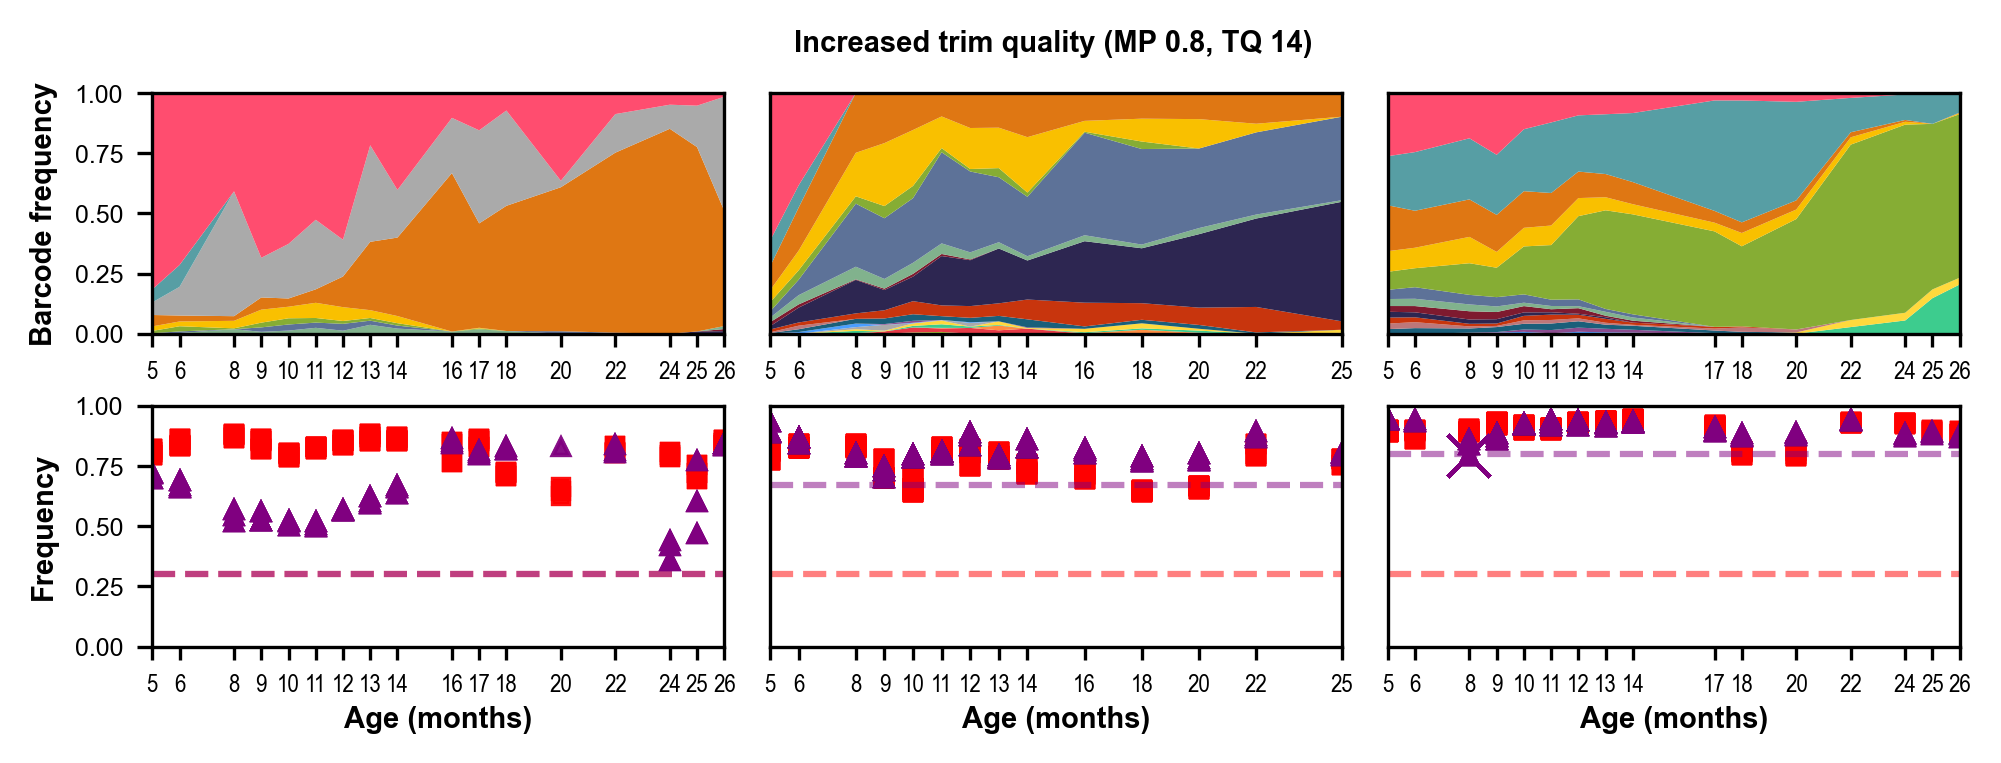

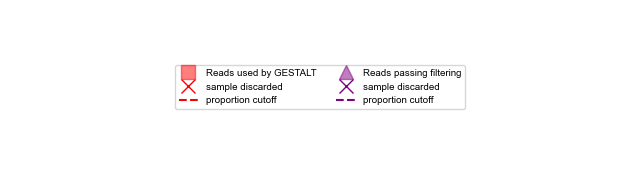

In [3]:
# Compare mullers for three sets of GESTALT parameters
# 4 fish, figure for paper

def plot_examples(data, metrics, fishes, exp):
    fig_width = 6.7  # 4 inches per column
    fig_height = 2.5
    
    fig, ax = plt.subplots(2, 3, figsize=(fig_width, fig_height), dpi=300)
    for i in range(3):
        ad.plot_fish(fishes[i], ax[0, i], data)
        ad.show_anomalies(fishes[i], ax[1, i], data, metrics, map_samples=True)
        ax[1, i].set_xticks(ax[0, i].get_xticks())
        ax[1, i].set_xlim(ax[0, i].get_xlim())
        ax[0, i].tick_params(axis='x', labelsize=6, length=3)
        ax[1, i].tick_params(axis='x', labelsize=6, length=3)
        if i > 0: 
            ax[0, i].set_ylabel('')
            ax[0, i].set_yticks([])
            ax[1, i].set_yticks([])
        else:
            ax[0, i].set_ylabel('Barcode frequency', fontweight = 'bold')
            ax[1, i].set_ylabel('Frequency', fontweight = 'bold')
        if exp == 'full_pipeline':
            ax[0, i].set_title(f'Fish {fishes[i][4:]}', fontweight = 'bold')
        else:
            ax[0, i].set_title(None)
        for label in ax[0, i].get_xticklabels() + ax[1, i].get_xticklabels():
            label.set_fontname('Arial Narrow')    
        ax[0, i].set_xlabel('')
        ax[1, i].set_xlabel('Age (months)', fontweight = 'bold', labelpad = 2)
    # plt.tight_layout()
    match exp:
        case 'full_pipeline': fig.suptitle('Original parameters (MP 0.8, TQ 10)', y = 1.02, x=0.525, fontweight='bold')
        case 'full_pipeline_MP0.95': fig.suptitle('Increased match proportion (MP 0.95, TQ 10)', x=0.525, fontweight='bold')
        case 'full_pipeline_TQ14': fig.suptitle('Increased trim quality (MP 0.8, TQ 14)', x=0.525, fontweight='bold')
            
    fig.subplots_adjust(wspace=0.08, hspace=0.3)
    plt.savefig(f'images/params/params_{exp}_plot.svg', format='svg')

fishes = ['fish5', 'fish14', 'fish38']

experiment1 = 'full_pipeline'
data_file1 = f'../experiments/{experiment1}/final_data.csv'
data1 = pd.read_csv(data_file1)
metrics1 = ad.get_anomaly_metrics(experiment1, data_folder='gestalt_output/mp0.8_tq10', root='../')

plot_examples(data1, metrics1, fishes, experiment1)

experiment2 = 'full_pipeline_MP0.95'
data_file2 = f'../experiments/{experiment2}/final_data.csv'
data2 = pd.read_csv(data_file2)
metrics2 = ad.get_anomaly_metrics(experiment2, data_folder='gestalt_output/mp0.95_tq10', root='../')

plot_examples(data2, metrics2, fishes, experiment2)

experiment3 = 'full_pipeline_TQ14'
data_file3 = f'../experiments/{experiment3}/final_data.csv'
data3 = pd.read_csv(data_file3)
metrics3 = ad.get_anomaly_metrics(experiment3, data_folder='gestalt_output/mp0.8_tq14', root='../')

plot_examples(data3, metrics3, fishes, experiment3)

# Create custom legend
legend_elements = [
    # Red square for "used entry prop"
    plt.Line2D([0], [0], marker='s', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=1, linestyle='None', alpha=0.5, 
               label='Reads used by GESTALT'),
    plt.Line2D([0], [0], marker='x', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=1, linestyle='None', 
               label='sample discarded'),
    plt.Line2D([0], [0], marker='None', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=1, linestyle='--', 
               label='proportion cutoff'),

    # Purple triangle for "kept entry prop"
    plt.Line2D([0], [0], marker='^', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=1, linestyle='None', alpha=0.5, 
               label='Reads passing filtering'),
    plt.Line2D([0], [0], marker='x', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=1, linestyle='None',
               label='sample discarded'),
    plt.Line2D([0], [0], marker='None', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=1, linestyle='--',
               label='proportion cutoff'),
]

# Create figure with no content
fig, ax = plt.subplots(figsize=(8, 2))
ax.set_axis_off()  # Hide axes

# Create legend with custom positioning
legend = ax.legend(handles=legend_elements, 
                   loc='center', 
                   ncol=2,  # Display in 2 columns
                   frameon=True)  # Keep frame

plt.savefig(f'images/params/params_legend.svg', format='svg')
plt.show()